In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# CHECK YOUR CURRENT NOTEBOOK LOCATION
import os
print(os.getcwd())

C:\Users\PRIYADARSHANI AICH\OneDrive\Desktop\E-commerce Sales & Customer Analytics


In [3]:
# Load the order dataset
orders= pd.read_csv("olist_orders_dataset.csv")

In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders.shape

(99441, 8)

In [6]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [7]:
# DATA CLEANING
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [8]:
#A- Check the exact count of missing values in each column
#B- Convert Date columns to datetime
#C-Check duplicate values
#D- View the count of each order status


In [9]:
#A- Check the exact count of missing values in each column
print(orders.isnull().sum())


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [10]:
#B- Convert Date columns to datetime
date_columns=['order_purchase_timestamp',
              'order_approved_at',
              'order_delivered_carrier_date',
              'order_delivered_customer_date',
              'order_estimated_delivery_date']
for col in date_columns:
    orders[col]=pd.to_datetime(orders[col])
print('Date columns converterd successfully!')

Date columns converterd successfully!


In [11]:
orders[["order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"]].isnull().sum()

order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

In [12]:
# ORDERS WITH MISSING APPROVAL DATES
print("Missing approval dates:")
print(orders.loc[orders["order_approved_at"].isna(),
    "order_status"].value_counts())

Missing approval dates:
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64


In [13]:
# Delivered 14 means the orders were delivered even though their approval timestamps are missing
orders.loc[orders["order_approved_at"].isna()
    & (orders["order_status"] == "delivered"),
    ["order_id","order_status","order_purchase_timestamp",
    "order_approved_at","order_delivered_carrier_date","order_delivered_customer_date",
    "order_estimated_delivery_date"]]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20
26800,c1d4211b3dae76144deccd6c74144a88,delivered,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27
39334,d77031d6a3c8a52f019764e68f211c69,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22
48401,7002a78c79c519ac54022d4f8a65e6e8,delivered,2017-01-19 22:26:59,NaT,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16
61743,2eecb0d85f281280f79fa00f9cec1a95,delivered,2017-02-17 17:21:55,NaT,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20


In [14]:
delivered_missing=orders[orders["order_approved_at"].isna()
    &(orders["order_status"]== "delivered")]
print(delivered_missing[["order_delivered_carrier_date","order_delivered_customer_date"]].isna().sum())

order_delivered_carrier_date     0
order_delivered_customer_date    0
dtype: int64


In [15]:
orders.loc[orders["order_approved_at"].isna()
    &(orders["order_status"]== "delivered"),[
    "order_id","order_purchase_timestamp","order_approved_at",
    "order_delivered_carrier_date","order_delivered_customer_date"
    ]].head()

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33
16567,8a9adc69528e1001fc68dd0aaebbb54a,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06
19031,7013bcfc1c97fe719a7b5e05e61c12db,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38
22663,5cf925b116421afa85ee25e99b4c34fb,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47
23156,12a95a3c06dbaec84bcfb0e2da5d228a,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19


In [16]:
orders[["order_delivered_carrier_date","order_delivered_customer_date"]].isna().sum()

order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

In [17]:
# Missing carrier dates by order status
print("Missing carrier dates:")
print(orders.loc[orders["order_delivered_carrier_date"].isna(),
    "order_status"].value_counts())

Missing carrier dates:
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64


In [18]:
# Missing customer delivery dates by order status
print("\nMissing customer delivery dates:")
print(orders.loc[
    orders["order_delivered_customer_date"].isna(),"order_status"
].value_counts())


Missing customer delivery dates:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [19]:
# What should we do with missing value
orders.loc[orders["order_delivered_customer_date"].isna()
    &(orders["order_status"]=="delivered"),
    ["order_id","order_purchase_timestamp","order_delivered_carrier_date","order_delivered_customer_date",
    "order_estimated_delivery_date"]]

,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-07-03 19:26:00,NaT,2018-07-19


In [20]:
delivered_missing=orders[
    orders["order_delivered_carrier_date"].isna()
    &(orders["order_status"] == "delivered")
]
print(delivered_missing[["order_id","order_delivered_carrier_date",
                        "order_delivered_customer_date","order_estimated_delivery_date"]].isna().sum())

order_id                         0
order_delivered_carrier_date     2
order_delivered_customer_date    1
order_estimated_delivery_date    0
dtype: int64


In [21]:
print(delivered_missing[["order_delivered_carrier_date",
                        "order_delivered_customer_date","order_estimated_delivery_date"]].isna().sum())

order_delivered_carrier_date     2
order_delivered_customer_date    1
order_estimated_delivery_date    0
dtype: int64


In [22]:
print("Number of delivered orders with missing custometr dates:")
print(len(delivered_missing))
print("\nMissing values within these orders:")
print(delivered_missing[["order_delivered_carrier_date",
                        "order_delivered_customer_date","order_estimated_delivery_date"]].isna().sum())

Number of delivered orders with missing custometr dates:
2

Missing values within these orders:
order_delivered_carrier_date     2
order_delivered_customer_date    1
order_estimated_delivery_date    0
dtype: int64


In [23]:
print("Number of rows:", len(delivered_missing))

print("Missing carrier dates:",
     delivered_missing["order_delivered_carrier_date"].isna().sum())
print("Missing customer dates:",
     delivered_missing["order_delivered_customer_date"].isna().sum())

Number of rows: 2
Missing carrier dates: 2
Missing customer dates: 1


In [24]:
# Handle Missing
# Filling Missing Value
orders['order_approved_at'] = orders['order_approved_at'].fillna(orders['order_purchase_timestamp'])

In [25]:
print(orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                   0
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [26]:
# Filling missing carrier dates for orders that were marked as 'delivered' using their approval date
orders.loc[
    (orders['order_delivered_carrier_date'].isna()) 
    &(orders['order_status'] == 'delivered'),'order_delivered_carrier_date'
] = orders['order_approved_at']

In [27]:
print(orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                   0
order_delivered_carrier_date     1781
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [28]:
orders.loc[
    (orders['order_delivered_customer_date'].isna()) 
    &(orders['order_status'] == 'delivered'),'order_delivered_customer_date'
] = orders['order_delivered_carrier_date']
print(orders.isnull().sum())


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                   0
order_delivered_carrier_date     1781
order_delivered_customer_date    2957
order_estimated_delivery_date       0
dtype: int64


In [29]:
#C-Check duplicate values
orders.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
99436    False
99437    False
99438    False
99439    False
99440    False
Length: 99441, dtype: bool

In [30]:
print("Duplicate orders IDs:",orders['order_id'].duplicated().sum())

Duplicate orders IDs: 0


In [31]:
#D- View the count of each order status
print(orders['order_status'].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [32]:
orders['delivery_time_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.days

In [33]:
orders['delivery_delay_days'] = (orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']).dt.days

In [34]:
orders['purchase_hour']= orders['order_purchase_timestamp'].dt.hour
orders['purchase_day_of_week']= orders['order_purchase_timestamp'].dt.day_name()

In [35]:
import pandas as pd

# List of all your Olist CSV file names
files = [
    'olist_customers_dataset.csv',
    'olist_geolocation_dataset.csv',
    'olist_order_items_dataset.csv',
    'olist_order_payments_dataset.csv',
    'olist_order_reviews_dataset.csv',
    'olist_products_dataset.csv',
    'olist_sellers_dataset.csv',
    'product_category_name_translation.csv'
]

# Loop through each file, load it, and print stats
for file in files:
    df = pd.read_csv(file)
    print(f"📁 Dataset: {file}")
    print(f"   Shape (Rows, Columns): {df.shape}")
    print(f"   Duplicate Rows: {df.duplicated().sum()}")
    print("   Null Values per Column:")
    print(df.isnull().sum())
    print(" DataTypes:")
    print(df.dtypes)
    print("-" * 50)

📁 Dataset: olist_customers_dataset.csv
   Shape (Rows, Columns): (99441, 5)
   Duplicate Rows: 0
   Null Values per Column:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
 DataTypes:
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object
--------------------------------------------------
📁 Dataset: olist_geolocation_dataset.csv
   Shape (Rows, Columns): (1000163, 5)
   Duplicate Rows: 261831
   Null Values per Column:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64
 DataTypes:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city          

In [36]:
# Drop duplicate rows in the geolocation dataset
geolocation_df = pd.read_csv('olist_geolocation_dataset.csv')


In [37]:
geolocation_df= geolocation_df.drop_duplicates()

In [38]:
print(f"New shape after dropping duplicates: {geolocation_df.shape}")

New shape after dropping duplicates: (738332, 5)


In [39]:
order_items_df= pd.read_csv('olist_order_items_dataset.csv')
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])

In [40]:
products_df= pd.read_csv('olist_products_dataset.csv')

In [41]:

num_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
products_df[num_cols] = products_df[num_cols].fillna(products_df[num_cols].median())

In [42]:
products_df['product_category_name']= products_df['product_category_name'].fillna('unknown')

In [43]:
num_cols = ['product_name_lenght','product_description_lenght','product_photos_qty']
for col in num_cols:
    products_df[col] =  products_df[col].fillna(products_df[col].median())

In [44]:
products_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32951 non-null  str    
 2   product_name_lenght         32951 non-null  float64
 3   product_description_lenght  32951 non-null  float64
 4   product_photos_qty          32951 non-null  float64
 5   product_weight_g            32951 non-null  float64
 6   product_length_cm           32951 non-null  float64
 7   product_height_cm           32951 non-null  float64
 8   product_width_cm            32951 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [45]:
payment_df=pd.read_csv('olist_order_payments_dataset.csv')

In [46]:
customers_df= pd.read_csv('olist_customers_dataset.csv')

In [47]:
items_df= pd.read_csv('olist_order_items_dataset.csv')

In [48]:
sellers_df= pd.read_csv('olist_sellers_dataset.csv')

In [49]:
category_translation_df= pd.read_csv('product_category_name_translation.csv')

In [50]:
reviews_df= pd.read_csv('olist_order_reviews_dataset.csv')

In [75]:
all_dfs= [orders,geolocation_df,order_items_df,products_df,payment_df,customers_df,sellers_df,category_translation_df,reviews_df]
for df in all_dfs:
    df.info()
    print("_" * 50)

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99441 non-null  datetime64[us]
 5   order_delivered_carrier_date   97660 non-null  datetime64[us]
 6   order_delivered_customer_date  96484 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
 8   delivery_time_days             96484 non-null  float64       
 9   delivery_delay_days            96484 non-null  float64       
 10  purchase_hour                  99441 non-null  int32         
 11  purchase_day_of_week      

In [76]:
review_cols = ['review_creation_date','review_answer_timestamp']
for col in review_cols:
    reviews_df[col] = pd.to_datetime(reviews_df[col])
    

In [77]:
reviews_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  str           
 1   order_id                 99224 non-null  str           
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  str           
 4   review_comment_message   40977 non-null  str           
 5   review_creation_date     99224 non-null  datetime64[us]
 6   review_answer_timestamp  99224 non-null  datetime64[us]
dtypes: datetime64[us](2), int64(1), str(4)
memory usage: 5.3 MB


In [78]:
# NOW DOING EDA PART
# Analze order status-- Find  out how many orders were delivered,canceled,shiped and so on

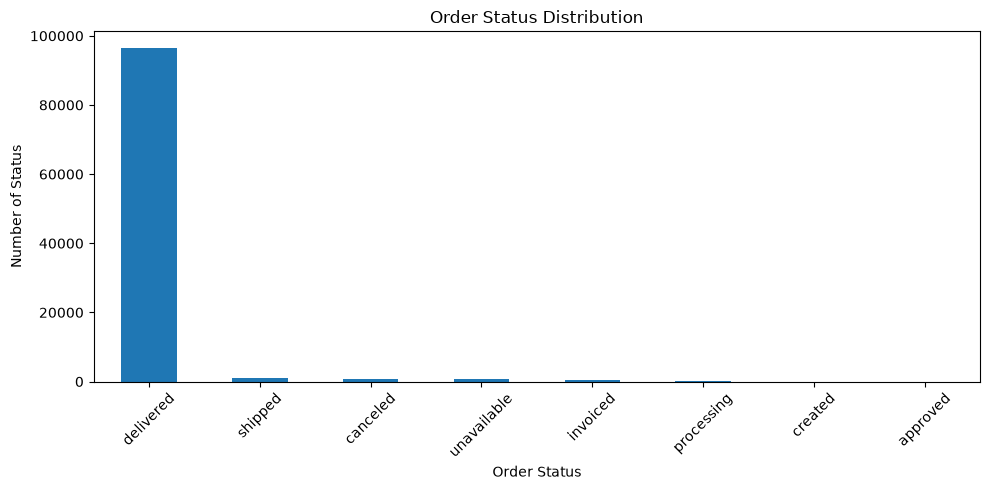

In [79]:
status_counts=orders["order_status"].value_counts()
plt.figure(figsize=(10,5))
status_counts.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Status")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [80]:
# Analyze delivery time
# On average, how many days does an order take to reach the customer

In [81]:
delivered_orders= orders[(orders["order_status"] == "delivered")
    & (orders["delivery_time_days"].notna())]

# Calculate average delivery time
avg_delivery = delivered_orders["delivery_time_days"].mean()
print("Average Delivery Time:", round(avg_delivery,2), "days")


Average Delivery Time: 12.09 days


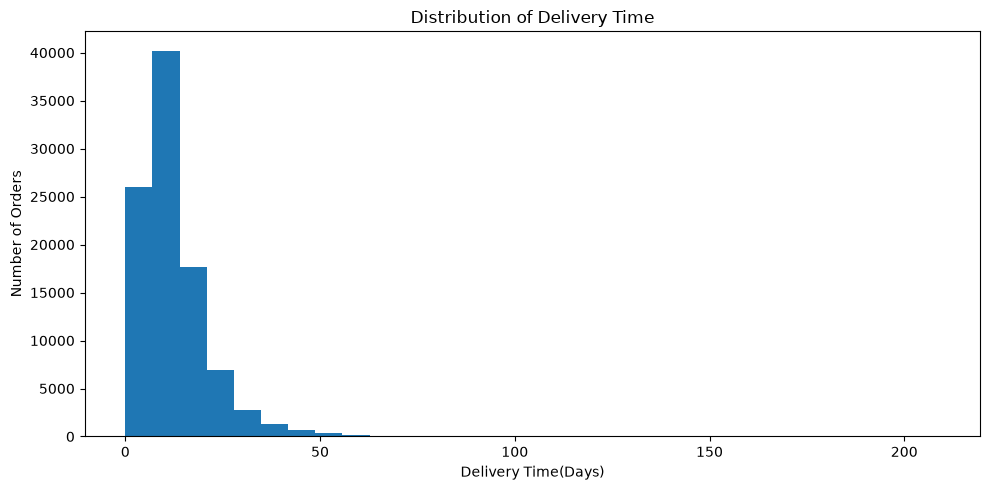

In [82]:
plt.figure(figsize=(10,5))
plt.hist(delivered_orders["delivery_time_days"] , bins=30)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time(Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [83]:
# Analyze late deliveries
# How many delivered orders arrived after their estimated delivery date ?

In [84]:
delivered_orders= orders[orders["order_status"] == "delivered"]

# count late, ontime,early deliveries
late_orders= (delivered_orders["delivery_delay_days"] > 0).sum()

on_time_or_early = (delivered_orders["delivery_delay_days"] <= 0).sum()

print("Late deliveries:", late_orders)
print("On_time or early deliveries:",on_time_or_early)

Late deliveries: 6534
On_time or early deliveries: 89944


In [85]:
# Analyze monthly order trends

# Extract month and year from purchase timestamp
orders["order_month"] = ( orders["order_purchase_timestamp"].dt.to_period("M"))

# Count unique orders from each month
monthly_orders= (orders.groupby("order_month")["order_id"].nunique())



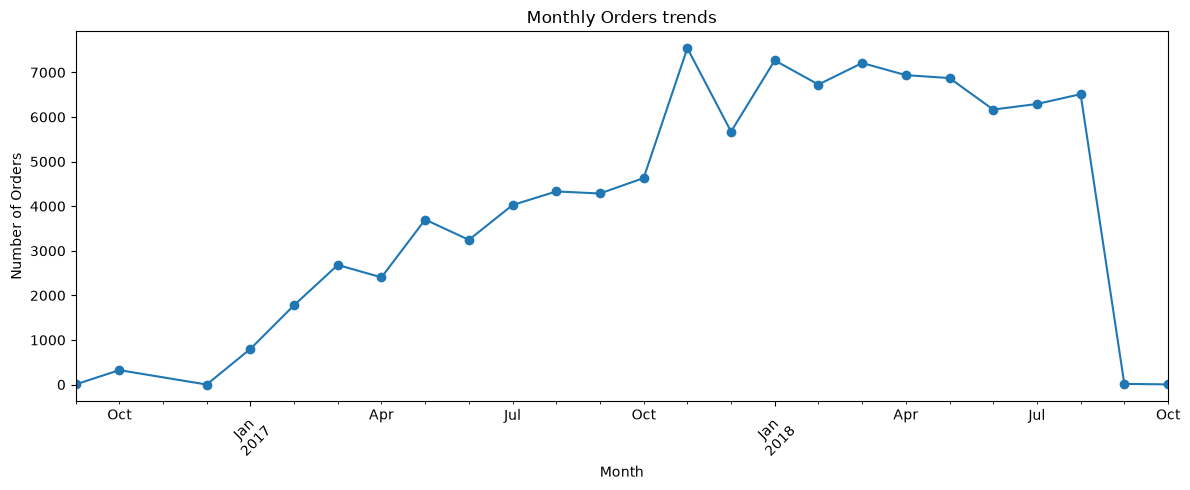

In [86]:
# plt monthly order trends
plt.figure(figsize=(12,5))
monthly_orders.plot(kind="line" , marker="o")

plt.title("Monthly Orders trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [87]:
# Which product categories generate the hignest revenue ?
items_products= items_df.merge(products_df[["product_id", "product_category_name"]], on="product_id", how="left")

# Calculate revenue by category
category_revenue= (items_products.groupby("product_category_name")["price"].sum().sort_values(ascending=False).head(10))

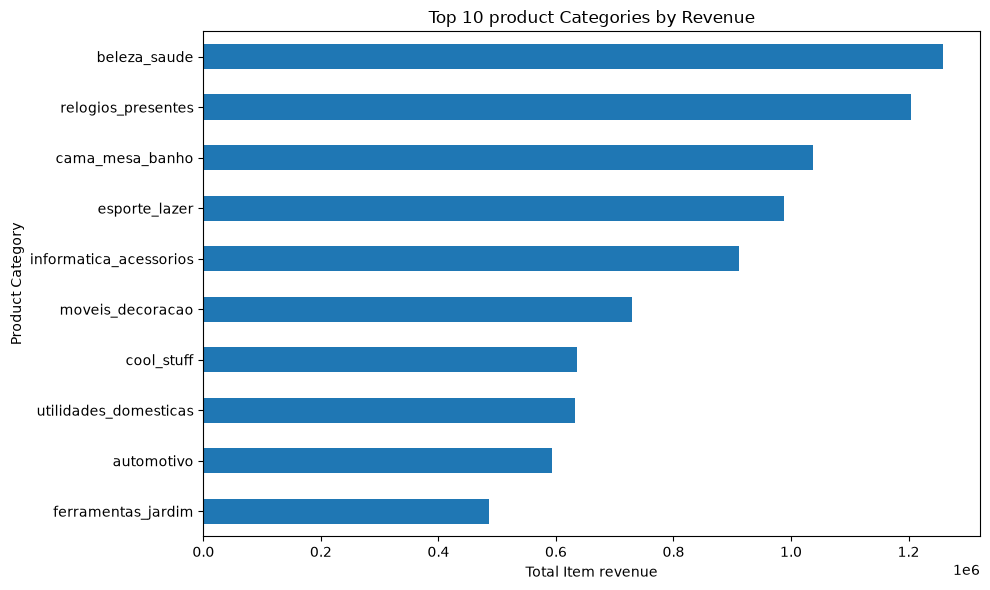

Top category: beleza_saude
Highest category revenue: 1258681.34


In [88]:
# Visulazation
category_revenue.sort_values().plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 product Categories by Revenue")
plt.xlabel("Total Item revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

print("Top category:", category_revenue.index[0])
print("Highest category revenue:", round(category_revenue.iloc[0], 2))

<Axes: ylabel='seller_id'>

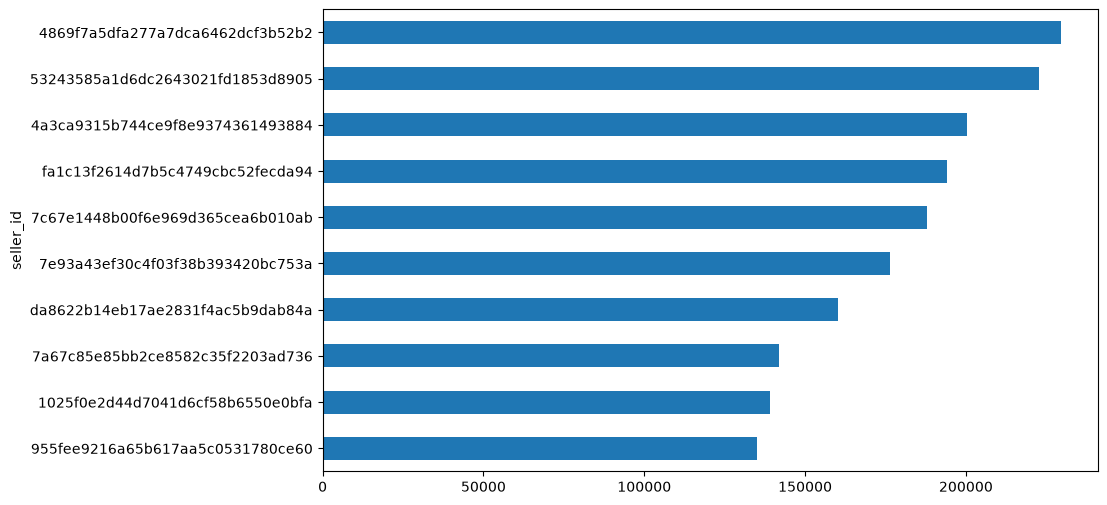

In [89]:
# Which sellers have the highest items revenue?
seller_revenue= (order_items_df.groupby("seller_id")["price"].sum().nlargest(10))

seller_revenue.sort_values().plot(kind="barh", figsize=(10,6))

In [94]:
# Payments EDA
# Which payment methods are most popular
payment_counts = payment_df["payment_type"].value_counts()

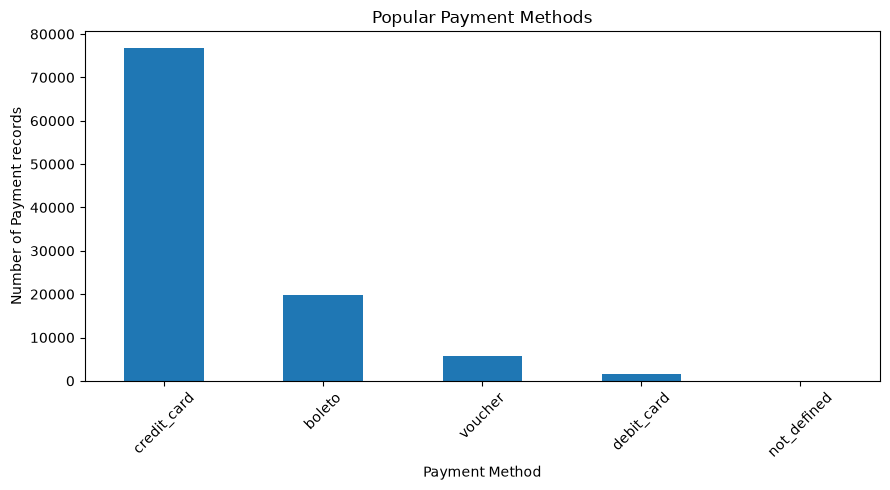

In [95]:
payment_counts.plot(kind="bar" , figsize=(9, 5))

plt.title("Popular Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of Payment records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [97]:
# Which payment methods contribute the most payment value ?

payment_value= (payment_df.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False))

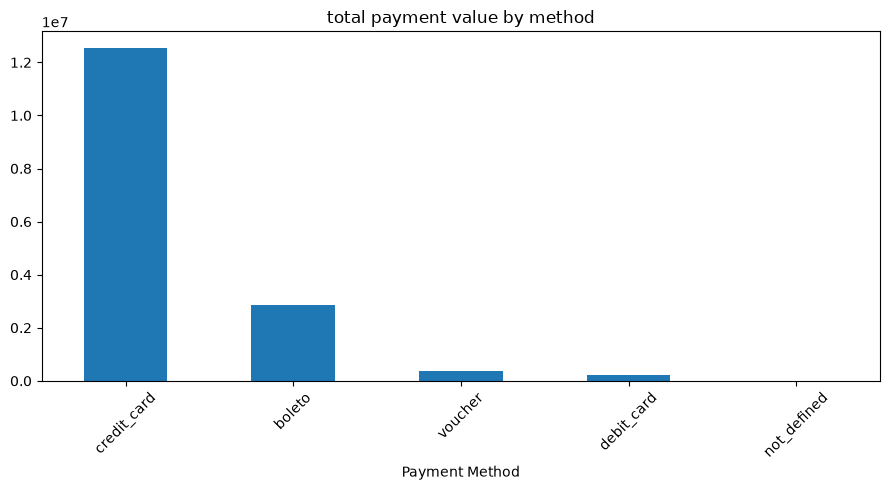

In [99]:
payment_value.plot(kind="bar", figsize=(9,5))

plt.title("total payment value by method")
plt.xlabel("Payment Method")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [101]:
# What is the distribution of installment counts ?

installments = payment_df["payment_installments"].value_counts().sort_index()


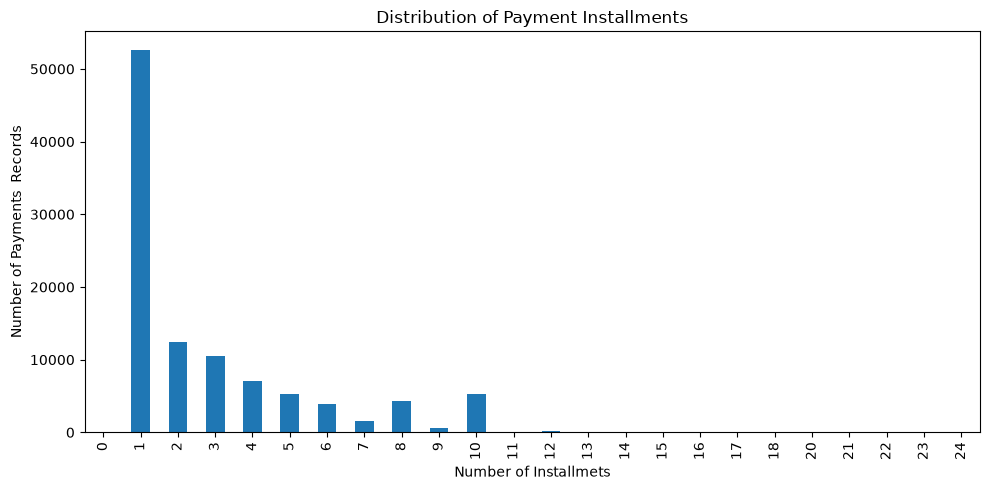

In [102]:
installments.plot(kind="bar", figsize=(10, 5))

plt.title("Distribution of Payment Installments")
plt.xlabel("Number of Installmets")
plt.ylabel("Number of Payments  Records")
plt.tight_layout()
plt.show()

In [103]:
reviews_df

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53
...,...,...,...,...,...,...,...
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07,2018-07-14 17:18:30
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09,2017-12-11 20:06:42
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22,2018-03-23 09:10:43
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01,2018-07-02 12:59:13


In [104]:
# What proportaion of reviews fall into each score?
review_pct= (reviews_df["review_score"].value_counts(normalize=True).sort_index() * 100)

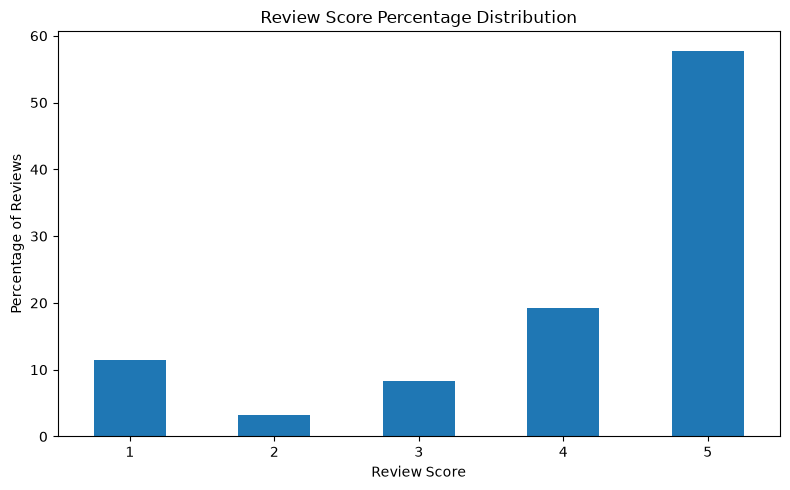

In [106]:
review_pct.plot(kind="bar" , figsize=(8, 5))
plt.title("Review Score Percentage Distribution")
plt.xlabel("Review Score")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [107]:
# How does review score vary with delivery delay?

order_reviews= orders.merge(reviews_df[["order_id", "review_score"]], on="order_id", how="inner")
order_reviews= order_reviews[order_reviews["delivery_delay_days"].notna()]

order_reviews["delivery_group"]= np.where(
    order_reviews["delivery_delay_days"]>0, "Late", "On time or early"
)

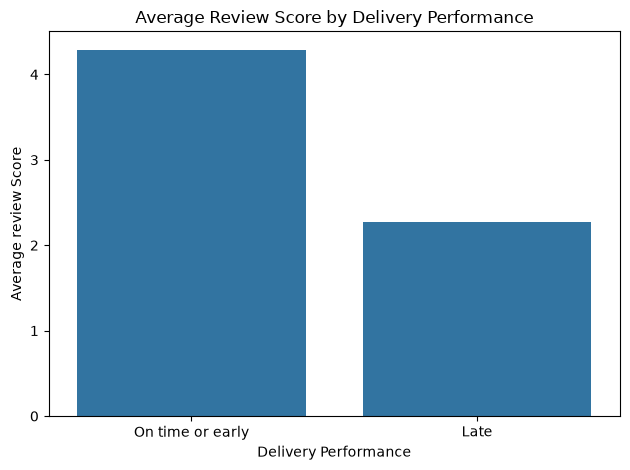

In [108]:
sns.barplot(
    data=order_reviews,
    x="delivery_group",
    y="review_score",
    errorbar=None
)

plt.title("Average Review Score by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average review Score")
plt.tight_layout()
plt.show()

In [109]:
customers_df

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [110]:
# Which states contribute the most customers ?
top_states = customers_df["customer_state"].value_counts().head(10)

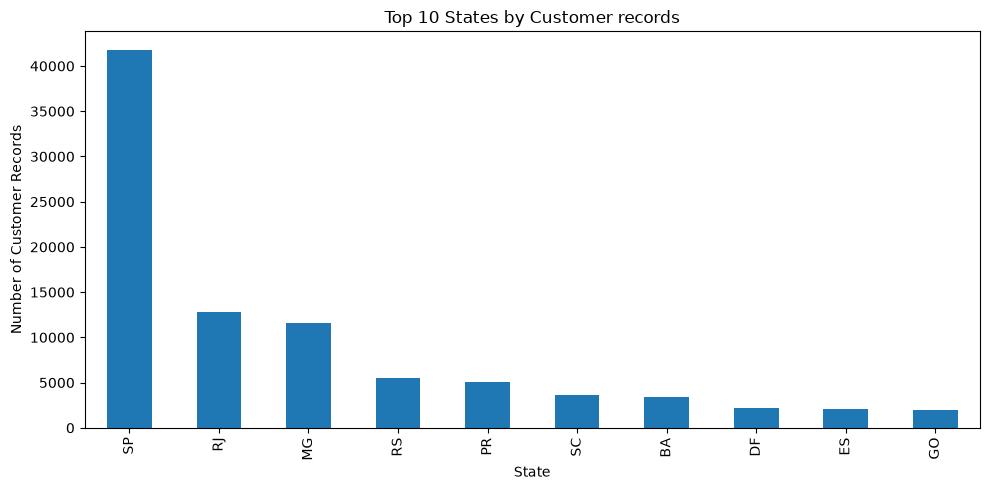

In [111]:
top_states.plot(kind ="bar" , figsize=(10, 5))

plt.title("Top 10 States by Customer records")
plt.xlabel("State")
plt.ylabel("Number of Customer Records")
plt.tight_layout()
plt.show()

In [112]:
# Which states generate the most order revenue?

customer_sales = (order_items_df.merge(orders[["order_id", "customer_id"]], on="order_id", how ="inner") 
                 .merge(customers_df[[ "customer_id","customer_state"]], on="customer_id" , how="left"))
state_revenue = (customer_sales.groupby("customer_state")["price"].sum().sort_values(ascending=False).head(10))

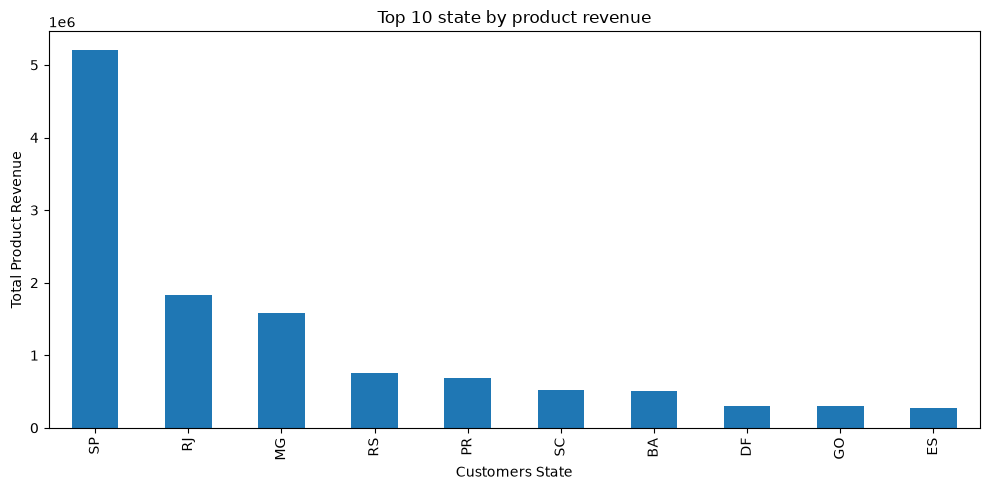

In [113]:
state_revenue.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 state by product revenue")
plt.xlabel("Customers State")
plt.ylabel("Total Product Revenue")
plt.tight_layout()
plt.show()

In [114]:
# Products EDA
# Which product categories have the most products?
products_df

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0
...,...,...,...,...,...,...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0


In [115]:
category_counts = (products_df["product_category_name"].value_counts().head(10))

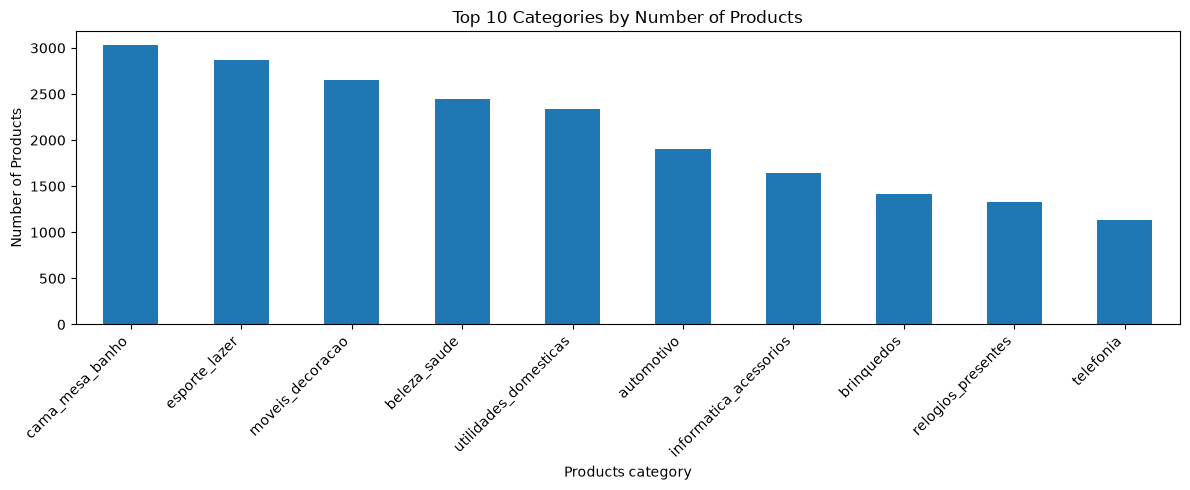

In [116]:
category_counts.plot(kind="bar" , figsize=(12,5))

plt.title("Top 10 Categories by Number of Products")
plt.xlabel("Products category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45 , ha="right")
plt.tight_layout()
plt.show()


In [117]:
# What is the relationship between product weight and dimensions?
product_dimensions = products_df.dropna(subset=["product_weight_g" , "product_length_cm"])

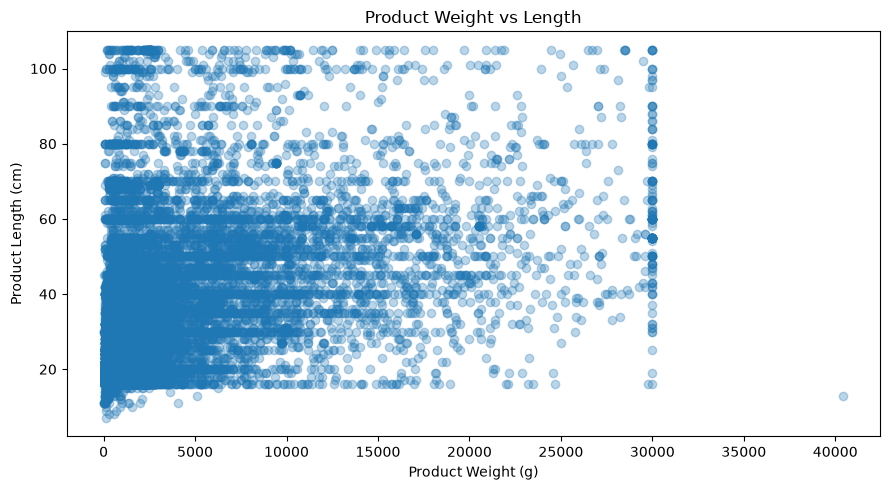

In [118]:
plt.figure(figsize=(9, 5))
plt.scatter(product_dimensions["product_weight_g"], product_dimensions["product_length_cm"], alpha=0.3)

plt.title("Product Weight vs Length")
plt.xlabel("Product Weight (g)")
plt.ylabel("Product Length (cm)")
plt.tight_layout()
plt.show()

In [119]:
sellers_df

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
...,...,...,...,...
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS


In [121]:
# Which sellers have the highest revenue ?
seller_revenue = (order_items_df.groupby("seller_id")["price"].sum().sort_values(ascending=False).head(10))

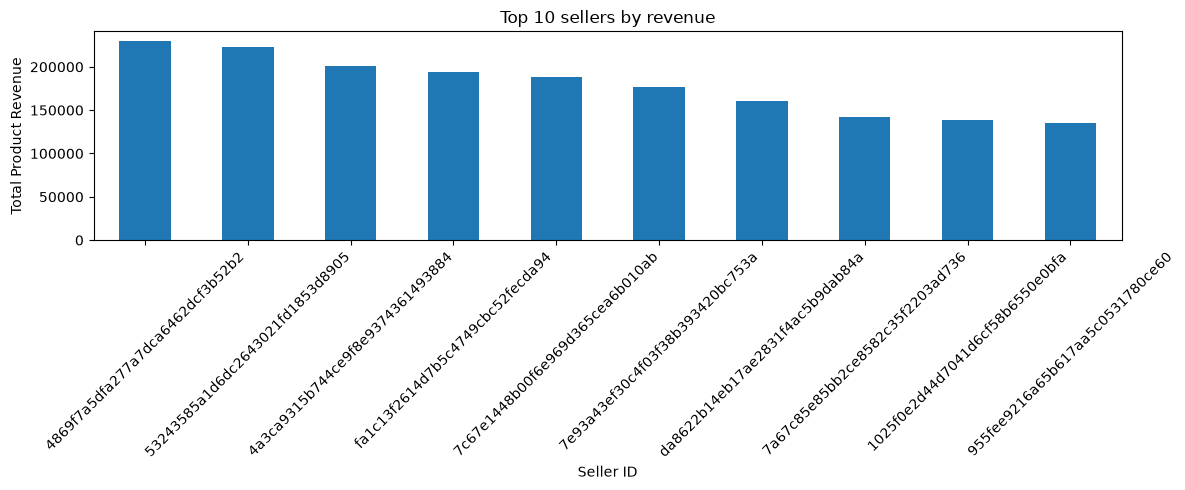

In [122]:
seller_revenue.plot(kind="bar", figsize=(12, 5))
plt.title("Top 10 sellers by revenue")
plt.xlabel("Seller ID")
plt.ylabel("Total Product Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [123]:
# Which seller states have the most sellers?
seller_state_count= sellers_df["seller_state"].value_counts().head(10)

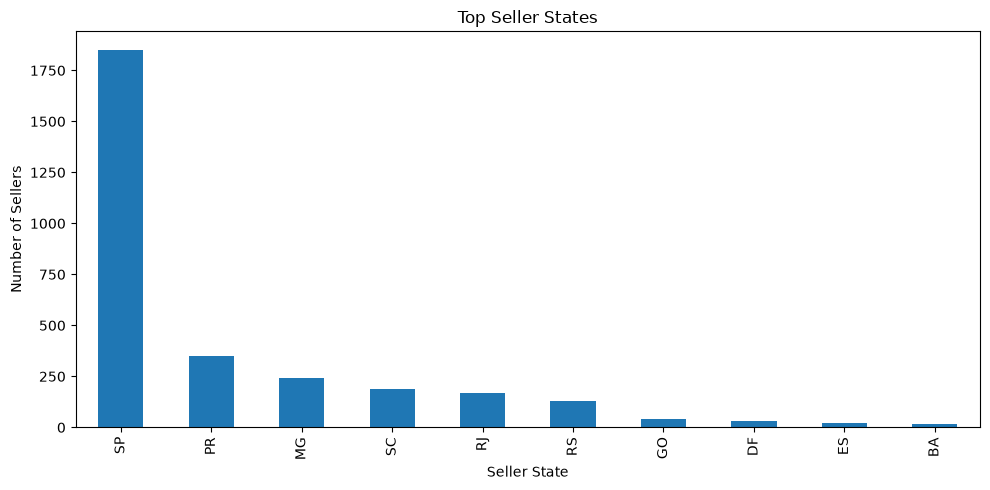

In [124]:
seller_state_count.plot(kind="bar" , figsize=(10,5))

plt.title("Top Seller States")
plt.xlabel("Seller State")
plt.ylabel("Number of Sellers")
plt.tight_layout()
plt.show()